In [51]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [52]:
df_cohort = pd.read_csv("../outputs/tables/cohort_retention_matrix.csv")
df_cohort.head(10)

,cohort_month,cohort_size,m0,m1,m2,m3,m4,m5,m6,m7,m8,m9,m10,m11,m12
0,2017-01,717,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,NaN,0.42,0.14,0.70
1,2017-02,1628,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12
2,2017-03,2503,100.0,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20
3,2017-04,2256,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04
4,2017-05,3451,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23
5,2017-06,3037,100.0,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16
6,2017-07,3752,100.0,0.53,0.35,0.24,0.29,0.21,0.32,0.11,0.19,0.27,0.21,0.29,0.13
7,2017-08,4057,100.0,0.69,0.35,0.27,0.35,0.52,0.30,0.27,0.15,0.15,0.25,0.20,0.12
8,2017-09,4004,100.0,0.70,0.55,0.27,0.45,0.22,0.22,0.25,0.27,0.17,0.25,0.07,NaN
9,2017-10,4328,100.0,0.72,0.25,0.09,0.23,0.21,0.21,0.37,0.28,0.18,0.21,NaN,NaN


In [53]:
df_cohort['cohort_label'] = df_cohort['cohort_month'] + ' (n=' + df_cohort['cohort_size'].apply(lambda x: f"{x:,}") + ')'
df_cohort.head(10)

,cohort_month,cohort_size,m0,m1,m2,m3,m4,m5,m6,m7,m8,m9,m10,m11,m12,cohort_label
0,2017-01,717,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,NaN,0.42,0.14,0.70,2017-01 (n=717)
1,2017-02,1628,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,"2017-02 (n=1,628)"
2,2017-03,2503,100.0,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20,"2017-03 (n=2,503)"
3,2017-04,2256,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04,"2017-04 (n=2,256)"
4,2017-05,3451,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23,"2017-05 (n=3,451)"
5,2017-06,3037,100.0,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16,"2017-06 (n=3,037)"
6,2017-07,3752,100.0,0.53,0.35,0.24,0.29,0.21,0.32,0.11,0.19,0.27,0.21,0.29,0.13,"2017-07 (n=3,752)"
7,2017-08,4057,100.0,0.69,0.35,0.27,0.35,0.52,0.30,0.27,0.15,0.15,0.25,0.20,0.12,"2017-08 (n=4,057)"
8,2017-09,4004,100.0,0.70,0.55,0.27,0.45,0.22,0.22,0.25,0.27,0.17,0.25,0.07,NaN,"2017-09 (n=4,004)"
9,2017-10,4328,100.0,0.72,0.25,0.09,0.23,0.21,0.21,0.37,0.28,0.18,0.21,NaN,NaN,"2017-10 (n=4,328)"


In [54]:
month_cols = [f'm{i}' for i in range(1, 13)]
heatmap_data = df_cohort.set_index('cohort_label')[month_cols]
heatmap_data.columns = [f'Month {i}' for i in range(1, 13)]
heatmap_data.head(10)

,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6,Month 7,Month 8,Month 9,Month 10,Month 11,Month 12
cohort_label,,,,,,,,,,,,
2017-01 (n=717),0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,NaN,0.42,0.14,0.70
"2017-02 (n=1,628)",0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12
"2017-03 (n=2,503)",0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20
"2017-04 (n=2,256)",0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04
"2017-05 (n=3,451)",0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23
"2017-06 (n=3,037)",0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16
"2017-07 (n=3,752)",0.53,0.35,0.24,0.29,0.21,0.32,0.11,0.19,0.27,0.21,0.29,0.13
"2017-08 (n=4,057)",0.69,0.35,0.27,0.35,0.52,0.30,0.27,0.15,0.15,0.25,0.20,0.12
"2017-09 (n=4,004)",0.70,0.55,0.27,0.45,0.22,0.22,0.25,0.27,0.17,0.25,0.07,NaN


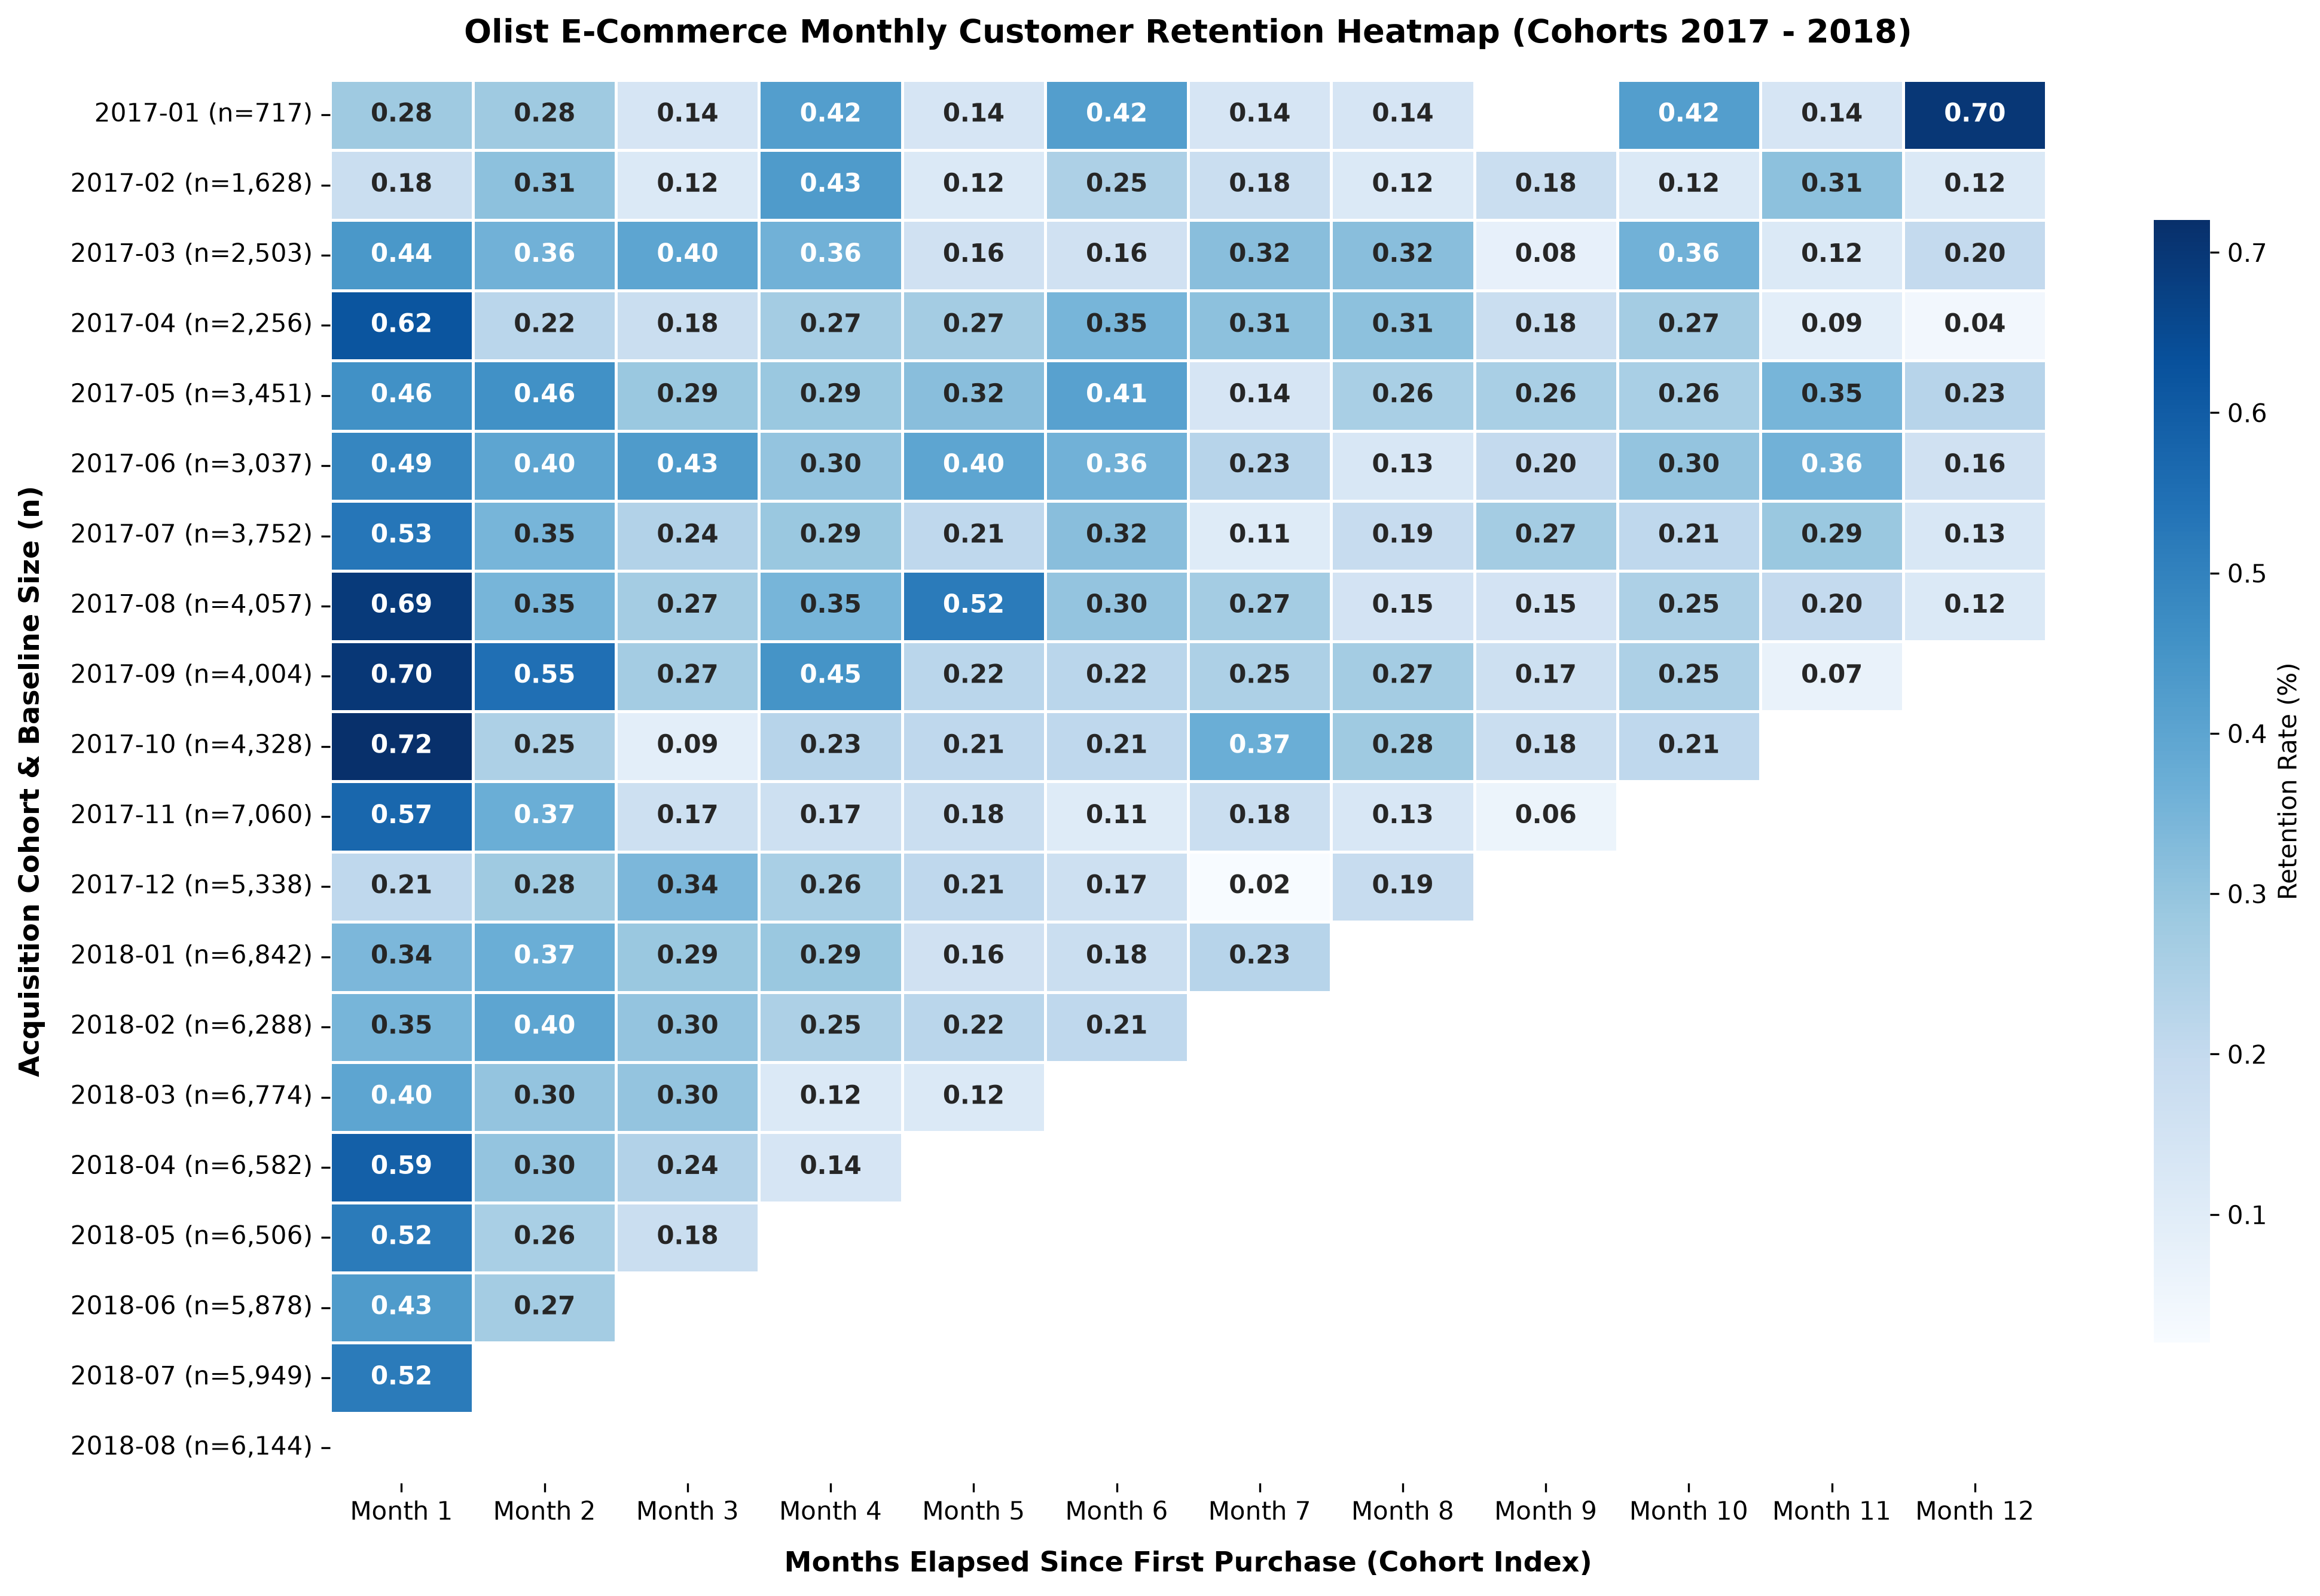

In [55]:
plt.figure(figsize=(14, 9), dpi=300)
mask = heatmap_data.isnull()
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    mask=mask,
    linewidths=0.75,
    linecolor="white",
    cbar_kws={'label': 'Retention Rate (%)', 'shrink': 0.8},
    annot_kws={'size': 10, 'weight': 'bold'}
)
plt.title('Olist E-Commerce Monthly Customer Retention Heatmap (Cohorts 2017 - 2018)', pad=15, fontsize=13, fontweight='bold')
plt.xlabel('Months Elapsed Since First Purchase (Cohort Index)', labelpad=10, fontsize=11, fontweight='bold')
plt.ylabel('Acquisition Cohort & Baseline Size (n)', labelpad=10, fontsize=11, fontweight='bold')
plt.tight_layout()

plt.savefig('../outputs/figures/01_cohort_retention_heatmap.png', dpi=300, bbox_inches='tight')

In [56]:
df_rfm = pd.read_csv('../outputs/tables/rfm_segment_summary.csv')
df_rfm = df_rfm.sort_values("Total Revenue", ascending=True).reset_index(drop=True)
df_rfm.head()

,Customer Segment,Total Customers,% Customers,Total Revenue,% Revenue,Avg Last Purchase (Days),Avg Order Frequency,Avg Spend (ARPU)
0,Loyal Customers,819,0.88,202926.35,1.32,183.5,2.07,247.77
1,At Risk,997,1.07,294583.92,1.91,381.8,2.08,295.47
2,Champions,985,1.06,366846.94,2.38,88.9,2.18,372.43
3,Recent Customers,10880,11.65,791151.64,5.13,45.2,1.00,72.72
4,Promising,10851,11.62,793976.00,5.15,135.6,1.00,73.17


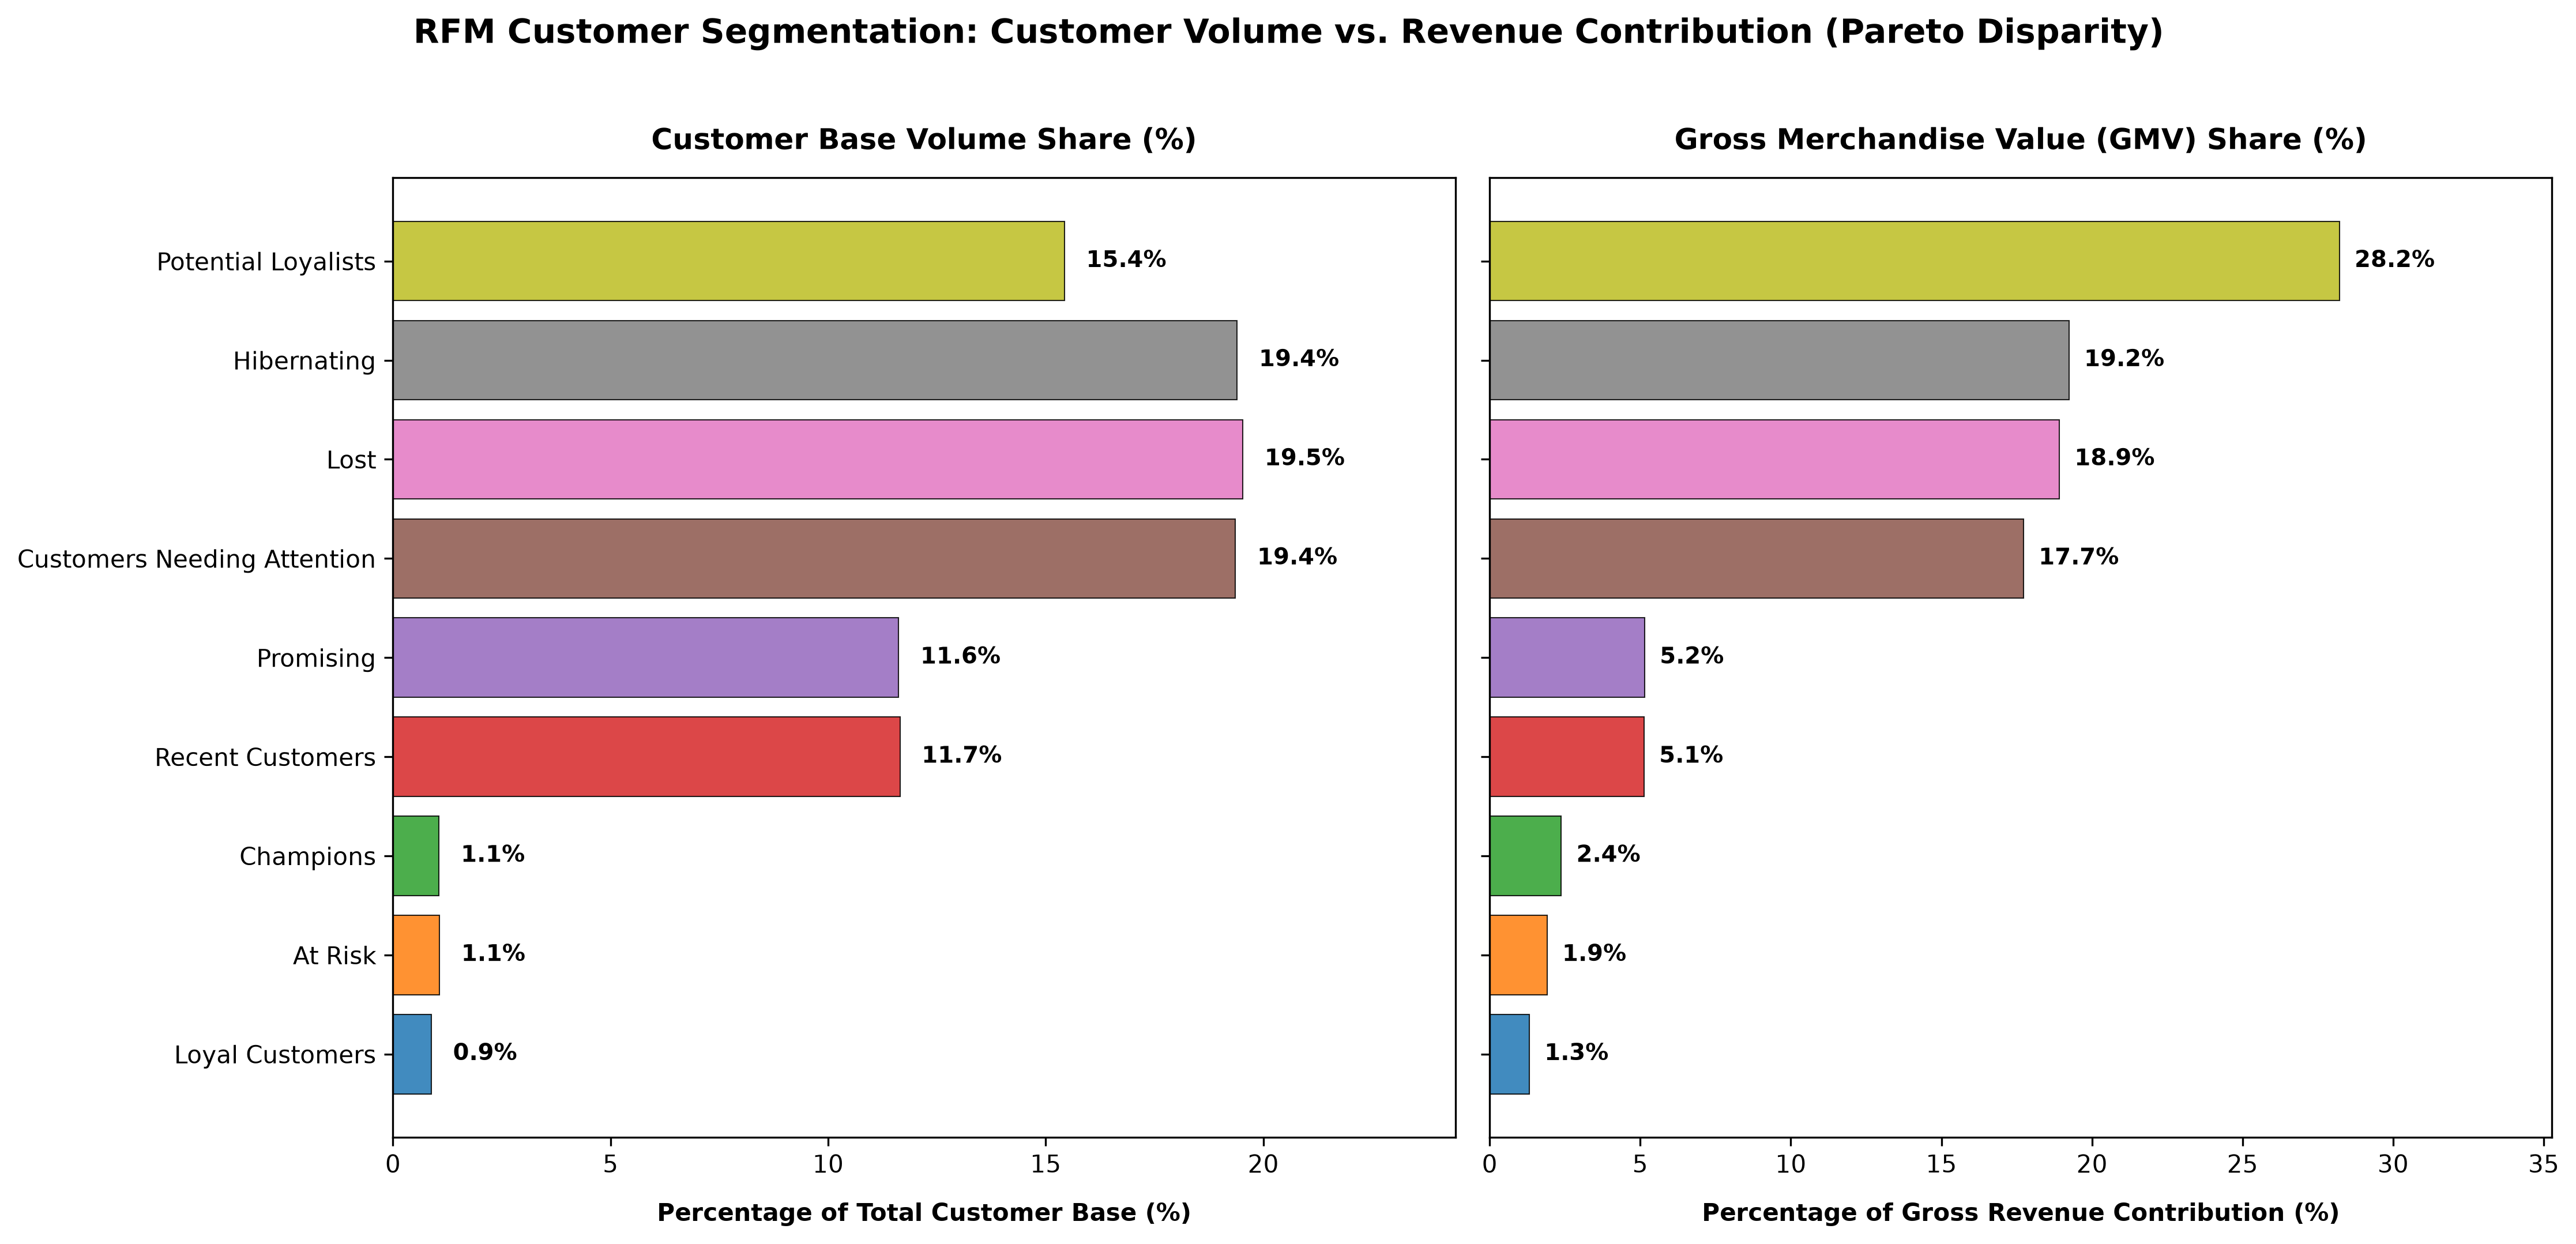

In [57]:
palette = sns.color_palette("tab10", len(df_rfm))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7), dpi=300, sharey=True)
bars1 = ax1.barh(df_rfm['Customer Segment'], df_rfm['% Customers'], color=palette, alpha=0.85, edgecolor='black', linewidth=0.5)
ax1.set_xlabel('Percentage of Total Customer Base (%)', labelpad=10, fontweight='bold')
ax1.set_title('Customer Base Volume Share (%)', pad=12, fontweight='bold')
ax1.set_xlim(0, max(df_rfm['% Customers']) * 1.25)

for bar in bars1:
    width = bar.get_width()
    ax1.text(width + 0.5, bar.get_y() + bar.get_height() / 2, f'{width:.1f}%',
             va='center', ha='left', fontsize=9.5, fontweight='bold')


bars2 = ax2.barh(df_rfm['Customer Segment'], df_rfm['% Revenue'], color=palette, alpha=0.85, edgecolor='black', linewidth=0.5)
ax2.set_xlabel('Percentage of Gross Revenue Contribution (%)', labelpad=10, fontweight='bold')
ax2.set_title('Gross Merchandise Value (GMV) Share (%)', pad=12, fontweight='bold')
ax2.set_xlim(0, max(df_rfm['% Revenue']) * 1.25)


for bar in bars2:
    width = bar.get_width()
    ax2.text(width + 0.5, bar.get_y() + bar.get_height() / 2, f'{width:.1f}%',
             va='center', ha='left', fontsize=9.5, fontweight='bold')

fig.suptitle('RFM Customer Segmentation: Customer Volume vs. Revenue Contribution (Pareto Disparity)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

plt.savefig('../outputs/figures/02_rfm_customer_and_revenue_distribution.png', dpi=300, bbox_inches='tight')

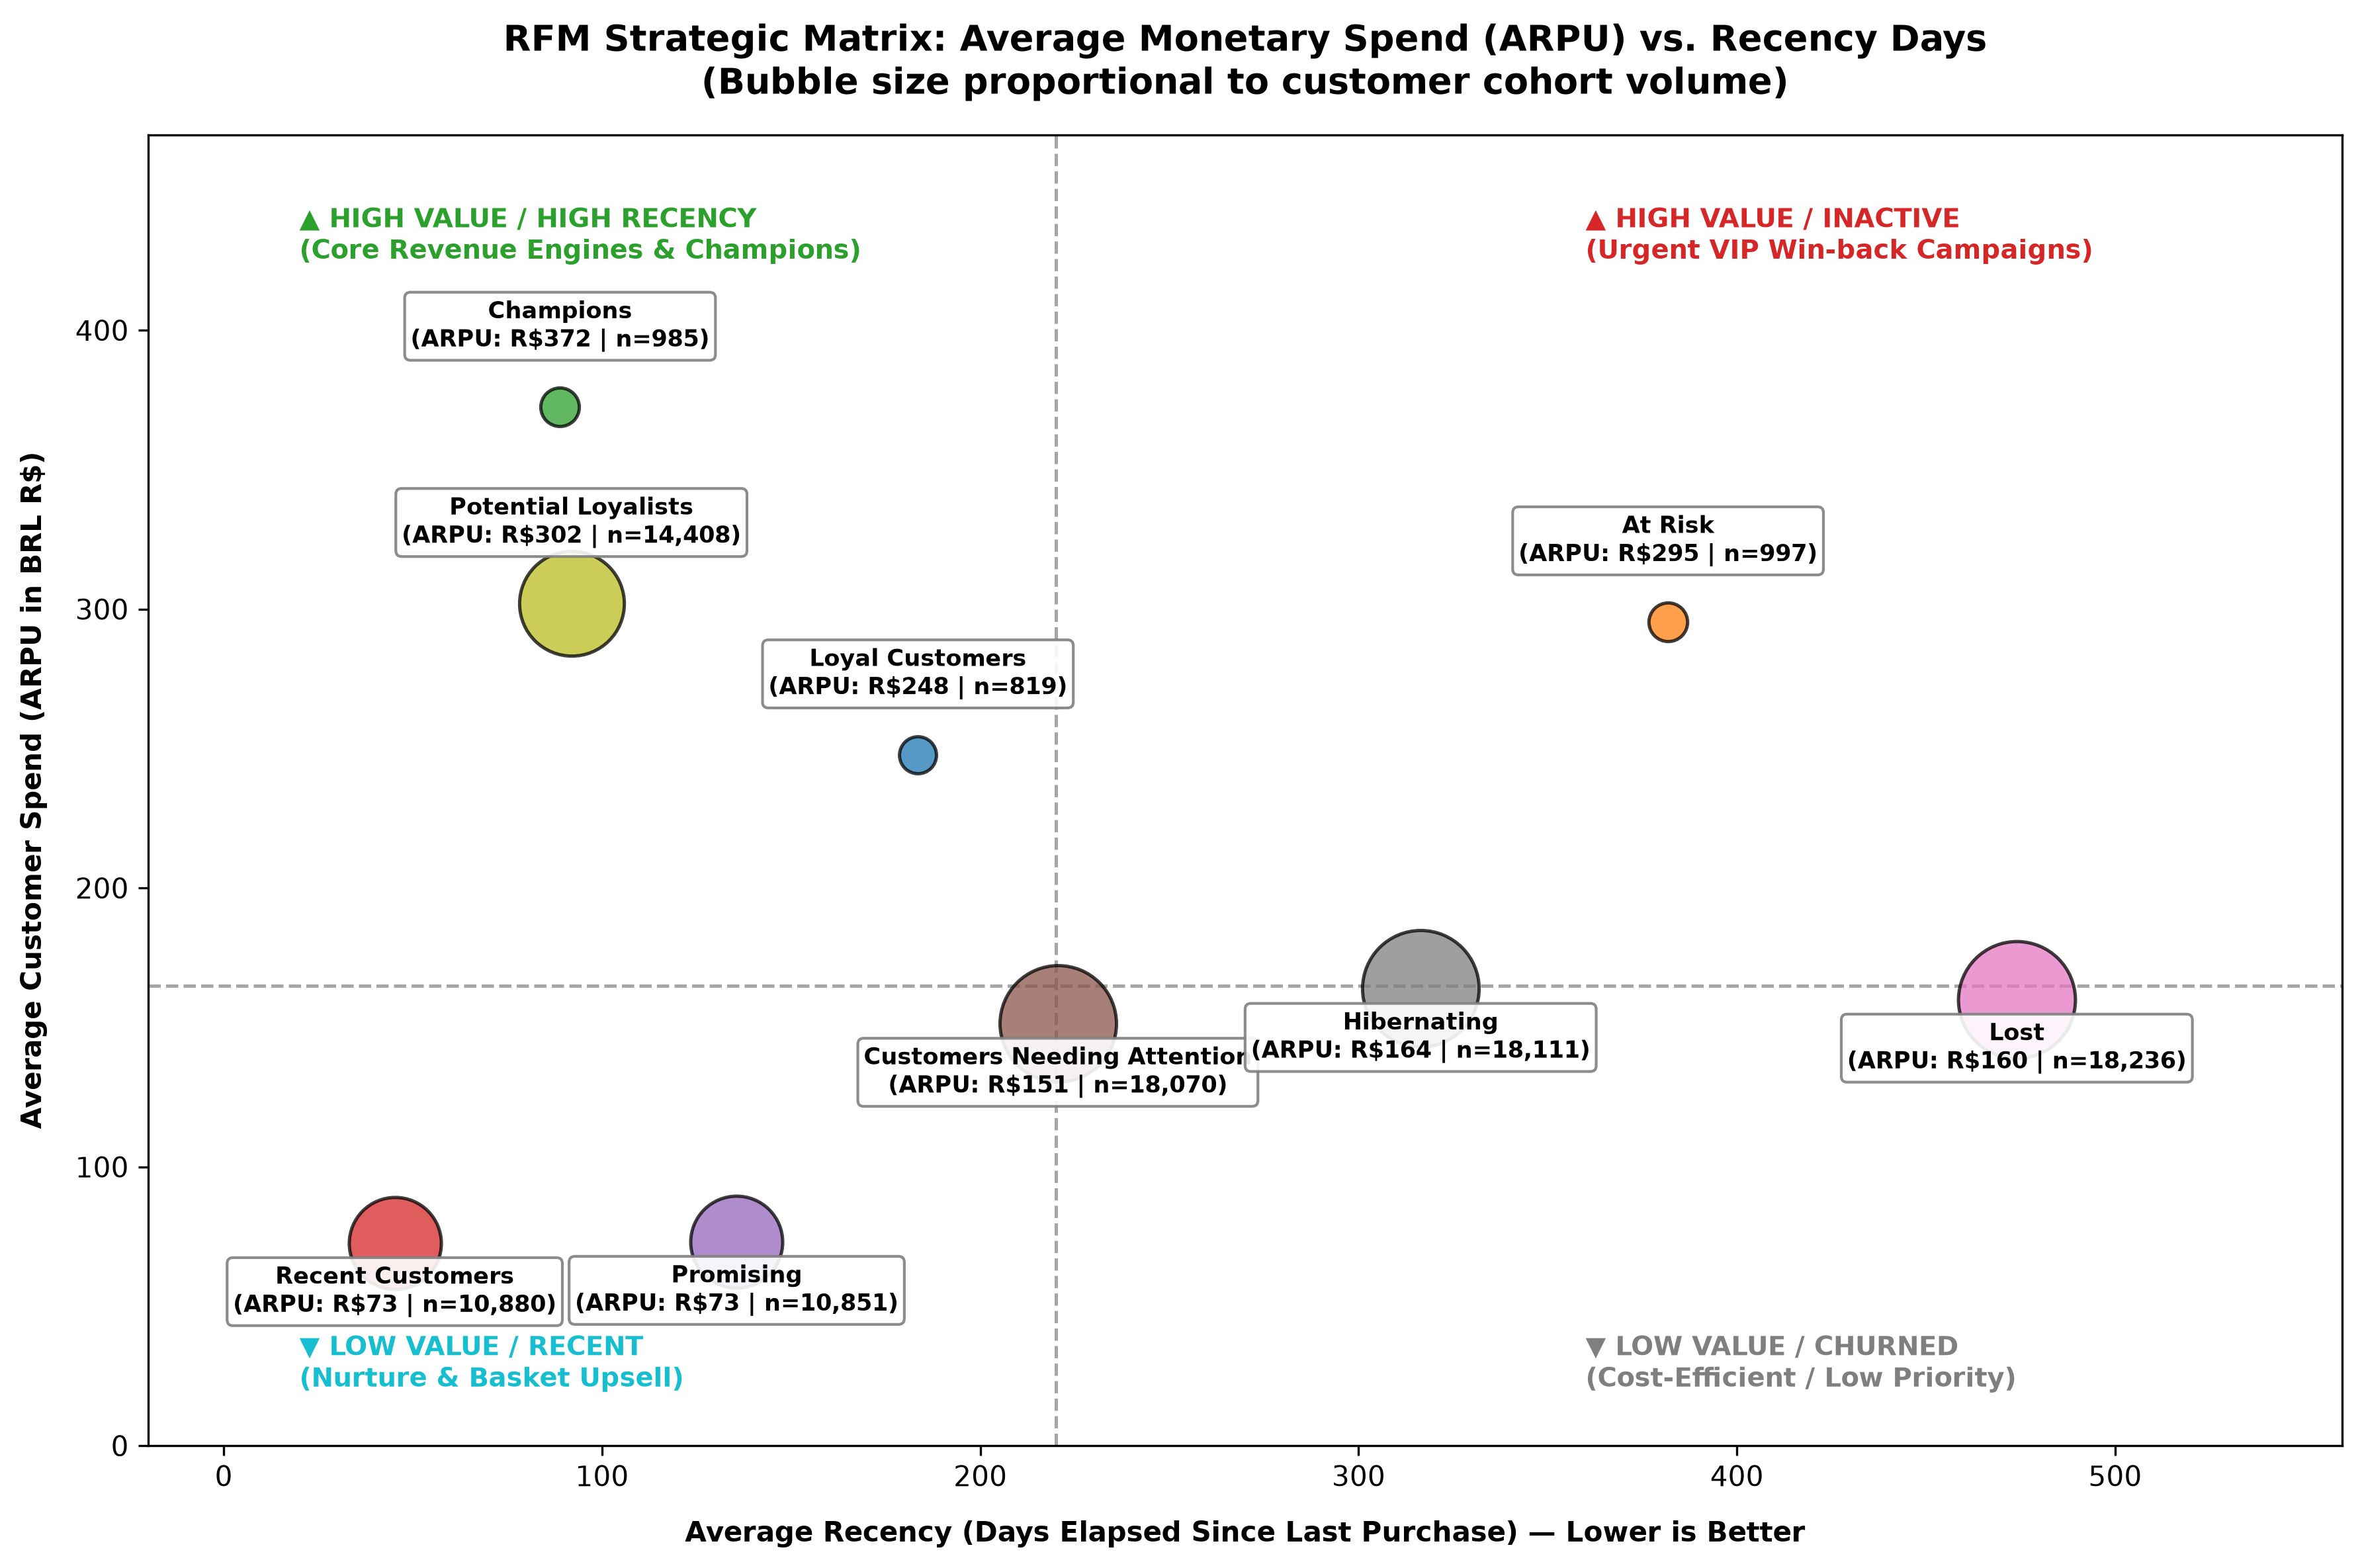

In [58]:

fig, ax = plt.subplots(figsize=(12, 8), dpi=300)


min_size = 180
max_size = 1800
norm_sizes = np.interp(df_rfm['Total Customers'], 
                       (df_rfm['Total Customers'].min(), df_rfm['Total Customers'].max()), 
                       (min_size, max_size))


for i, row in df_rfm.iterrows():
    ax.scatter(
        row['Avg Last Purchase (Days)'],
        row['Avg Spend (ARPU)'],
        s=norm_sizes[i],
        alpha=0.75,
        edgecolors='black',
        linewidth=1.2,
        zorder=3
    )
    
    
    offset_y = 22 if row['Avg Spend (ARPU)'] > 200 else -25
    ax.annotate(
        f"{row['Customer Segment']}\n(ARPU: R${row['Avg Spend (ARPU)']:.0f} | n={row['Total Customers']:,})",
        (row['Avg Last Purchase (Days)'], row['Avg Spend (ARPU)']),
        textcoords="offset points",
        xytext=(0, offset_y),
        ha='center',
        fontsize=8.5,
        fontweight='bold',
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="gray", alpha=0.9, lw=1),
        zorder=4
    )


ax.axvline(220, color='gray', linestyle='--', linewidth=1.2, alpha=0.7)
ax.axhline(165, color='gray', linestyle='--', linewidth=1.2, alpha=0.7)


ax.text(20, 445, "▲ HIGH VALUE / HIGH RECENCY\n(Core Revenue Engines & Champions)", fontsize=9.5, color='#2ca02c', fontweight='bold', va='top')
ax.text(360, 445, "▲ HIGH VALUE / INACTIVE\n(Urgent VIP Win-back Campaigns)", fontsize=9.5, color='#d62728', fontweight='bold', va='top')
ax.text(20, 18, "▼ LOW VALUE / RECENT\n(Nurture & Basket Upsell)", fontsize=9.5, color='#17becf', fontweight='bold', va='bottom')
ax.text(360, 18, "▼ LOW VALUE / CHURNED\n(Cost-Efficient / Low Priority)", fontsize=9.5, color='#7f7f7f', fontweight='bold', va='bottom')


ax.set_title('RFM Strategic Matrix: Average Monetary Spend (ARPU) vs. Recency Days\n(Bubble size proportional to customer cohort volume)', pad=15, fontweight='bold', fontsize=13)
ax.set_xlabel('Average Recency (Days Elapsed Since Last Purchase) — Lower is Better', labelpad=10, fontweight='bold')
ax.set_ylabel('Average Customer Spend (ARPU in BRL R$)', labelpad=10, fontweight='bold')
ax.set_xlim(-20, 560)
ax.set_ylim(0, 470)

plt.tight_layout()


plt.savefig('../outputs/figures/03_rfm_strategic_quadrant.png', dpi=300, bbox_inches='tight')